---
# Grammar Filtering For Syntax-Guided Synthesis <span style="font-size: 0.6em; position: relative; top: -0.2em;">[[PDF]](https://arxiv.org/pdf/2002.02884)</span>
---

In [1]:
import gzip, json, random, re, subprocess, time
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

from IPython.display import HTML
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm.notebook import tqdm
from tensorflow import keras
from tensorflow.keras import layers, optimizers


In [2]:
for name in ('grammar.sl', 'cache.json.gz', 'model.keras', 'benchmarks.zip'):
    urlretrieve(f'https://zenodo.org/records/23712343/files/{name}', name)

ZipFile('benchmarks.zip').extractall()

In [3]:
NUMBER_OF_PROGRAMS      = 15_000 
CONSTRAINTS_PER_PROGRAM = 10     # We start with 15K * 10 = 150K data points (paper ends up with 124,928 after *filtering*)
CANDIDATE_TERMINALS     = 2      # Pluck out the top K terminals where A_g > 0 (paper uses 3)...
TERMINALS_TO_REMOVE     = 1      # ...and predict which N of these should be removed (paper uses 2). These two are grammar-specific (ours only has 2 terminals with A_g > 0)
USE_CUTOFF              = False  # Whether or not to use the "fall-back" strategy described in eq (2) of the paper (the paper ends up not using it)
SYNTHESIS_TIMEOUT       = 3600

RANDOM_SEED             = 42
CACHE_PATH              = Path('cache.json.gz')
MODEL_PATH              = Path('model.keras')

cache = json.load(gzip.open(CACHE_PATH, 'rt')) if CACHE_PATH.exists() else {}
model = keras.models.load_model(MODEL_PATH) if MODEL_PATH.exists() else None

# Benchmark and grammar files use *values*. CVC4 accepts these but emits the *keys*. This matters when building training labels and counting program sizes
ALIASES = {'str.from_int': 'int.to.str', 'str.to_int': 'str.to.int'}

In [4]:
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
keras.utils.set_random_seed(RANDOM_SEED)

## Data Generation

In [5]:
with open('grammar.sl') as f:
    grammar = f.read()

print(terminals := tuple(dict.fromkeys(re.findall(r'\(([^\s()]+)\s+nt\w+', grammar))))

('str.++', 'str.replace', 'str.at', 'int.to.str', 'str.substr', '+', '-', 'str.len', 'str.to.int', 'str.indexof')


In [6]:
def generate_programs(grammar):
    proc = subprocess.Popen(
        ['cvc4', '--sygus-stream', '--lang', 'sygus1'],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
        stderr=subprocess.DEVNULL,
        text=True,
    )
    proc.stdin.write(grammar)
    proc.stdin.close()

    programs = [line.rstrip('\n') for _, line in tqdm(zip(range(NUMBER_OF_PROGRAMS), proc.stdout), total=NUMBER_OF_PROGRAMS, desc="Programs")]

    proc.terminate()
    random.shuffle(programs)
    return programs

In [7]:
def generate_constraints(programs):
    kept_programs = []
    constraints = []
    for program in tqdm(programs, desc="Constraints"):
        name = program.split()[1]
        for _ in range(CONSTRAINTS_PER_PROGRAM):
            inp = "".join(chr(random.randint(32, 90)) for _ in range(random.randint(1, 20)))
            out = subprocess.run(
                ['cvc4', '--lang', 'smt2'],
                input=f'(set-logic ALL)\n{program}\n(simplify ({name} "{inp.replace(chr(34), chr(34) * 2)}"))\n',
                stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True,
            ).stdout.strip()[1:-1].replace(chr(34) * 2, chr(34))
            if len(out) <= 20:
                kept_programs.append(program)
                constraints.append((inp, out))
    return kept_programs, constraints

In [8]:
if 'programs' not in cache:
    cache['programs'] = generate_programs(grammar)
    json.dump(cache, gzip.open(CACHE_PATH, 'wt'))

if 'constraints' not in cache or len(cache['programs']) != len(cache['constraints']):
    cache['programs'], cache['constraints'] = generate_constraints(cache['programs'])
    json.dump(cache, gzip.open(CACHE_PATH, 'wt'))

programs = cache['programs']
constraints = cache['constraints']

total_constraints = NUMBER_OF_PROGRAMS * CONSTRAINTS_PER_PROGRAM
print(f'KEPT {len(constraints):,} / {total_constraints:,} DATA POINTS')

KEPT 148,994 / 150,000 DATA POINTS


In [9]:
if 'time_benchmarks' in cache:
    time_benchmarks = cache['time_benchmarks']
else:
    with open('benchmarks/human.json') as f:
        human_benchmarks = [list(benchmark.items()) for benchmark in json.load(f)]
    time_benchmarks = human_benchmarks + [(constraint,) for constraint in random.sample(constraints, 20)]
    cache['time_benchmarks'] = time_benchmarks
    json.dump(cache, gzip.open(CACHE_PATH, 'wt'))

In [10]:
# Turns a G and a C into a (G, C)
def make_problem(grammar, constraints):
    body = '\n'.join(f'(constraint (= (f "{inp}") "{out}"))' for inp, out in constraints)
    return grammar.replace('(check-synth)', f'{body}\n(check-synth)')

# Turns a G into a G* (subset grammar where the selected terminals have been removed)
def reduce(grammar, *terminals):
    for terminal in terminals:
        grammar = re.sub(rf'\({re.escape(terminal)}\s[^()]*\)', '', grammar)
    return grammar

# Solves a (G, C), yielding the synthesized P and the synthesis time
def solve(problem, timeout=SYNTHESIS_TIMEOUT):
    t_0 = time.perf_counter()
    try:
        proc = subprocess.run(
            ['cvc4', '--lang', 'sygus1'],
            input=problem,
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.DEVNULL,
            timeout=timeout,
        )
    except subprocess.TimeoutExpired:
        return '', timeout
    lines = proc.stdout.splitlines()
    return lines[-1] if lines else '', time.perf_counter() - t_0

In [11]:
TR_crit = list(zip(constraints, programs))
TR_time = cache.get('TR_time', [])
TR_full = {int(k): v for k, v in cache.get('TR_time_full', {}).items()}

# We populate TR_time with this checkpointing loop. It allows us to safely interrupt the cell throughout
if len(TR_time) < len(time_benchmarks) * len(terminals):
    with tqdm(total=len(time_benchmarks) * len(terminals), initial=len(TR_time), desc="TR_time") as pbar:
        for bi, C in enumerate(time_benchmarks):
            if (bi + 1) * len(terminals) <= len(TR_time):
                continue
            if bi not in TR_full:
                TR_full[bi] = solve(make_problem(grammar, C))[1]
                cache['TR_time_full'] = TR_full
                json.dump(cache, gzip.open(CACHE_PATH, 'wt'))
            full = TR_full[bi]
            for ti, t in enumerate(terminals):
                if bi * len(terminals) + ti < len(TR_time):
                    continue
                delta = full - solve(make_problem(reduce(grammar, t), C))[1]
                TR_time.append((C, t, delta))
                cache['TR_time'] = TR_time
                json.dump(cache, gzip.open(CACHE_PATH, 'wt'))
                pbar.update(1)

In [12]:
if 'A_g' in cache:
    A_g = np.asarray(cache['A_g'])
else:
    A_g = np.array([d for *_, d in TR_time]).reshape(-1, len(terminals)).mean(axis=0)
    cache['A_g'] = A_g.tolist()
    json.dump(cache, gzip.open(CACHE_PATH, 'wt'))
    
pd.DataFrame({'TERMINAL': terminals, 'A_g': A_g}).sort_values('A_g', ascending=False)

,TERMINAL,A_g
1,str.replace,0.099057
4,str.substr,0.072119
2,str.at,-0.019407
6,-,-0.044631
5,+,-0.139474
8,str.to.int,-0.139966
7,str.len,-0.592178
9,str.indexof,-17.344315
0,str.++,-120.414548
3,int.to.str,-839.806153


## Criticality

In [13]:
def encode(constraints):
    return np.array([[ord(c) for c in inp[:20].ljust(20, '\0') + out[:20].ljust(20, '\0')] for inp, out in constraints], dtype=np.int32)

X = encode(pair for pair, _ in TR_crit)
y = np.array([[float(t in {ALIASES.get(token, token) for token in re.findall(r'[^\s()]+', program)}) for t in terminals] for _, program in TR_crit], dtype=np.float32)

In [14]:
# Split by program so all constraints from one program stay on the same side
unique_programs = list(dict.fromkeys(program for _, program in TR_crit))
train_programs = set(unique_programs[:int(0.8 * len(unique_programs))])

train = np.array([i for i, (_, program) in enumerate(TR_crit) if program in train_programs])
val   = np.array([i for i, (_, program) in enumerate(TR_crit) if program not in train_programs])

In [15]:
if model is None:
    model = keras.Sequential([
        layers.Input(shape=(40,), dtype="int32"),
        layers.Embedding(input_dim=128, output_dim=100),
        layers.Flatten(),
        # Dropout rate is not specified in the paper, we opt for a fixed 0.5 across all layers
        *[layer for n in range(1, 4) for layer in (layers.Dense(round(4000 * (len(terminals) / 4000) ** (n / 4)), activation="sigmoid"), layers.Dropout(0.5))],
        layers.Dense(len(terminals), activation="sigmoid"),
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
    )

    fit = model.fit(
        X[train],
        y[train],
        epochs=15,
        batch_size=200,
        validation_data=(X[val], y[val]),
        verbose=0
    )
    history = fit.history
    cache['history'] = history
    json.dump(cache, gzip.open(CACHE_PATH, 'wt'))
    model.save(MODEL_PATH)

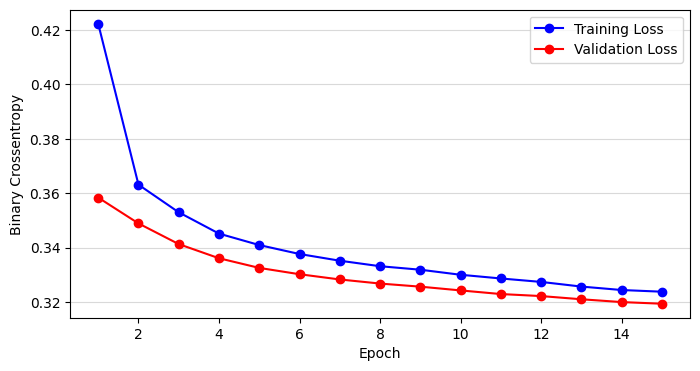

In [16]:
history = cache['history']
epochs = range(1, len(history['loss']) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, history['loss'], marker='o', color="blue", label='Training Loss')
ax.plot(epochs, history['val_loss'], marker='o', color="red", label='Validation Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary Crossentropy')
ax.grid(axis='y', color='0.85')
ax.legend();

## Results

In [17]:
# Looks at the top K terminals where A_g > 0 and predicts which N of these should be removed
def predict_terminals(constraints):
    votes = (model.predict(encode(constraints), verbose=0) > 0.5).sum(axis=0)
    candidates = sorted(((a, int(v), t) for a, v, t in zip(A_g, votes, terminals) if a > 0), reverse=True)[:CANDIDATE_TERMINALS]
    return [t for _, _, t in sorted(candidates, key=lambda item: item[1])[:TERMINALS_TO_REMOVE]]

# Plucks out a set of benchmarks (i.e. the ones for figures 2, 3 and 4)
def get_benchmarks(name=None):
    if name is None:
        return sorted(Path('benchmarks').glob('*.sl'))
    filenames = Path(f'benchmarks/{name}.txt').read_text().splitlines()
    return [Path('benchmarks') / filename for filename in filenames]

# Grabs the G in a (G, C) 
def get_grammar(problem):
    return '\n'.join(line for line in problem.splitlines() if not line.strip().startswith('(constraint')) + '\n'

# Grabs the C in a (G, C)
def get_constraints(problem):
    return tuple(re.findall(r'\(constraint\s+\(=\s+\(f\s+"([^"]*)"\)\s+"([^"]*)"\)\)', problem))

# Counts the number of terminals in a (synthesized) program
def program_length(program):
    return None if not program else sum(ALIASES.get(token, token) in terminals for token in re.findall(r'[^\s()]+', program))

# Takes a dataframe (figure), a y-axis label, and the col names for the white & black bars. Plots a bar chart comparing the chosen cols
def plot(figure, ylabel, white_col, black_col):
    xs, width = np.arange(len(figure)), 0.25
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_axisbelow(True)
    ax.bar(xs - width / 2, figure[white_col].fillna(0), width, facecolor='white', edgecolor='black', linewidth=0.9, label='CVC4')
    ax.bar(xs + width / 2, figure[black_col].fillna(0), width, color='black', edgecolor='black', linewidth=0.9, label='GRT + CVC4')
    ax.set_xticks(xs, figure['ID'])
    ax.set_xlabel('Benchmark ID')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', color='0.85')
    ax.legend()

In [18]:
if 'T' in cache and 'T_star' in cache:
    T, T_star = cache['T'], cache['T_star']
else:
    T = [solve(make_problem(grammar, C))[1] for C in tqdm(time_benchmarks, desc="T")]
    T_star = [solve(make_problem(reduce(grammar, *predict_terminals(C)), C))[1] for C in tqdm(time_benchmarks, desc="T_star")]
    cache['T'], cache['T_star'] = T, T_star
    json.dump(cache, gzip.open(CACHE_PATH, 'wt'))

x = min(
    [0, *T_star],
    key=lambda cutoff: sum(
        g_star if g_star <= cutoff else min(cutoff + g, SYNTHESIS_TIMEOUT)
        for g, g_star in zip(T, T_star)
    )
)

T_cutoff = [
    g_star if g_star <= x else min(x + g, SYNTHESIS_TIMEOUT)
    for g, g_star in zip(T, T_star)
]
T_selected = T_cutoff if USE_CUTOFF else T_star

print(f"x = {x:.2f}s (MEAN W/O REMOVAL: {np.mean(T):.2f}s, MEAN W/ REMOVAL: {np.mean(T_star):.2f}s)")

x = 0.34s (MEAN W/O REMOVAL: 0.26s, MEAN W/ REMOVAL: 0.04s)


In [19]:
benchmarks = get_benchmarks('fig-4')
results = cache.get('benchmark_results', {})
rows = []

for ID, benchmark in tqdm(zip(range(34, 34 + len(benchmarks)), benchmarks), total=len(benchmarks), desc='Benchmarks', disable=len(results) == len(benchmarks)):
    if benchmark.name not in results:
        problem = benchmark.read_text()
        C = get_constraints(problem)
        removed = predict_terminals(C)
        P, T_G = solve(problem)
        P_star, T_G_star = solve(make_problem(reduce(get_grammar(problem), *removed), C), timeout=x if USE_CUTOFF else SYNTHESIS_TIMEOUT)
        if USE_CUTOFF and not P_star:
            T_G_star = min(x + T_G, SYNTHESIS_TIMEOUT)
            P_star = P if P and x + T_G <= SYNTHESIS_TIMEOUT else ''
        results[benchmark.name] = [P, P_star, T_G, T_G_star, program_length(P), program_length(P_star)]
        cache['benchmark_results'] = results
        json.dump(cache, gzip.open(CACHE_PATH, 'wt'))
    rows.append([ID, benchmark.name, *results[benchmark.name]])

figure4 = pd.DataFrame(rows, columns=['ID', 'BENCHMARK', 'P', 'P*', 'T_G^C', 'T_G*^C', '|P|', '|P*|'])

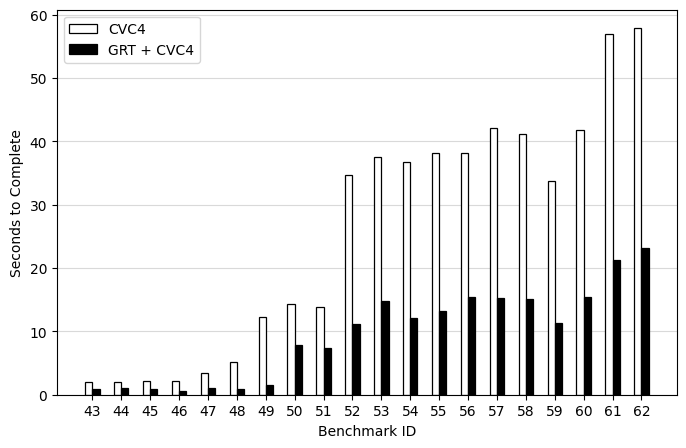

In [20]:
figure_2 = figure4[figure4['BENCHMARK'].isin([path.name for path in get_benchmarks('fig-2')])]
plot(figure_2, 'Seconds to Complete', 'T_G^C', 'T_G*^C')

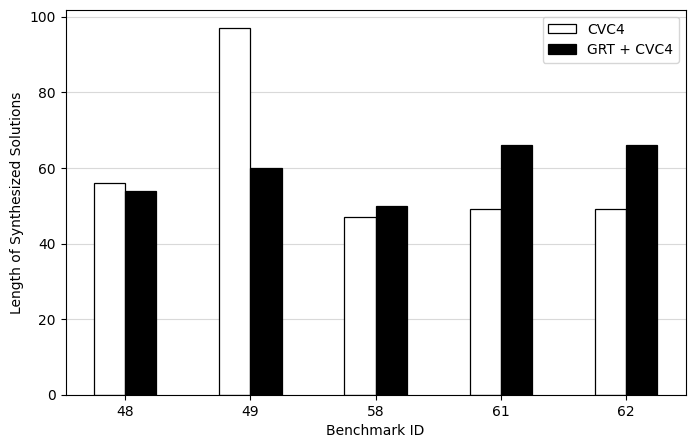

In [21]:
figure_3 = figure4[figure4['BENCHMARK'].isin([path.name for path in get_benchmarks('fig-3')])]
plot(figure_3, 'Length of Synthesized Solutions', '|P|', '|P*|')

In [22]:
pd.DataFrame({
    'ID': figure4['ID'],
    'BENCHMARK': figure4['BENCHMARK'],
    'T_G^C': ['TO' if not P else f'{T:.2f}' for P, T in zip(figure4['P'], figure4['T_G^C'])],
    'T_G*^C': ['TO' if not P else f'{T:.2f}' for P, T in zip(figure4['P*'], figure4['T_G*^C'])],
    '|P|': ['-' if pd.isna(length) else int(length) for length in figure4['|P|']],
    '|P*|': ['-' if pd.isna(length) else int(length) for length in figure4['|P*|']],
}).style.hide(axis='index')

ID,BENCHMARK,T_G^C,T_G*^C,|P|,|P*|
34,lastname_small.sl,0.79,0.51,4,4
35,bikes-long.sl,0.83,0.60,3,3
36,bikes-long-repeat.sl,0.79,0.59,3,3
37,lastname.sl,1.03,0.58,4,4
38,phone-6_short.sl,1.42,0.53,11,11
39,phone-7_short.sl,1.58,0.64,11,11
40,initials-long-repeat.sl,1.52,0.99,7,7
41,phone-5_short.sl,1.84,0.68,9,9
42,phone-7.sl,2.14,0.83,11,11
43,phone-8.sl,2.04,0.95,11,11


In [23]:
T_G_total = sum(T if P else SYNTHESIS_TIMEOUT for P, T in zip(figure4['P'], figure4['T_G^C']))
T_G_star_total = sum(T if P else SYNTHESIS_TIMEOUT for P, T in zip(figure4['P*'], figure4['T_G*^C']))
reduction = 100 * (1 - T_G_star_total / T_G_total)

print(f'TOTAL REDUCTION: {reduction:.2f}% (CVC4+GFT: {T_G_star_total:.2f}s, CVC4: {T_G_total:.2f}s)')

TOTAL REDUCTION: 62.73% (CVC4+GFT: 196.95s, CVC4: 528.46s)
